# 03. Logistic Regression Classifier

Baseline linear classification model for relationship compatibility.

In [2]:
# ============================================================
# Imports et configuration
# ============================================================
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Convention commune de l'équipe (identique dans src/data/preprocessing.py)
RANDOM_STATE = 42
N_SPLITS = 5

print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


In [5]:
# ============================================================
# Chemins du projet et import du code commun (dossier src/)
# ============================================================
def find_project_root():
    cwd = Path.cwd().resolve()
    for folder in [cwd, *cwd.parents]:
        if (folder / "src" / "data" / "preprocessing.py").exists() and (folder / "data" / "raw").exists():
            return folder
    raise FileNotFoundError(
        "Racine du projet introuvable (dossiers 'src' et 'data/raw' attendus). "
        "Lancez le notebook depuis le dossier du projet."
    )

ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_PATH = ROOT / "data" / "raw" / "cupid_algorithm_dataset.csv"
FIGURES_DIR = ROOT / "results" / "figures"
TABLES_DIR = ROOT / "results" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

try:
    from src.data.preprocessing import CupidDataPreprocessor
    from src.models.logistic_regression import CupidLogisticRegression
    from src.evluation.metrics import evaluate_classification_model, print_evaluation_summary
    from src.evluation.cross_validation import run_cross_validation
except ImportError as error:
    raise ImportError(
        "Import du code commun impossible. Installez les dépendances avec : "
        "pip install -r requirement.txt  (xgboost est requis par src/models)."
    ) from error

print("Racine du projet :", ROOT)
print("Données brutes   :", RAW_PATH)

Racine du projet : C:\Users\PC\Desktop\projet-FDD\DM_PROJECT
Données brutes   : C:\Users\PC\Desktop\projet-FDD\DM_PROJECT\data\raw\cupid_algorithm_dataset.csv


In [6]:
# ============================================================
# Prétraitement commun et découpage train / test
# ============================================================
preprocessor = CupidDataPreprocessor(test_size=0.2, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = preprocessor.prepare_train_test(str(RAW_PATH))

FEATURE_NAMES = list(preprocessor.feature_names)
CAT_NAMES = preprocessor.encoder.named_transformers_["cat"].get_feature_names_out(
    preprocessor.categorical_cols
).tolist()
NUM_NAMES = [name for name in FEATURE_NAMES if name not in CAT_NAMES]

# Contrôles de cohérence
for forbidden in ["compatibility_score", "relationship_longevity_months", "pair_id"]:
    assert forbidden not in FEATURE_NAMES, f"La colonne '{forbidden}' ne doit pas être utilisée."
assert X_train.shape[1] == X_test.shape[1] == len(FEATURE_NAMES)
assert not np.isnan(X_train).any() and not np.isnan(X_test).any(), "Valeurs manquantes détectées."

print(f"Train : {X_train.shape[0]:,} lignes x {X_train.shape[1]} variables ({y_train.mean():.2%} de compatibles)")
print(f"Test  : {X_test.shape[0]:,} lignes x {X_test.shape[1]} variables ({y_test.mean():.2%} de compatibles)")
print(f"\nVariables : {len(CAT_NAMES)} indicatrices (one-hot), {len(NUM_NAMES)} numériques")
print("Variables brutes :", len(preprocessor.numerical_raw_cols),
      "| variables construites :", len(NUM_NAMES) - len(preprocessor.numerical_raw_cols))

Train : 80,000 lignes x 73 variables (42.88% de compatibles)
Test  : 20,000 lignes x 73 variables (42.88% de compatibles)

Variables : 36 indicatrices (one-hot), 37 numériques
Variables brutes : 20 | variables construites : 17


In [7]:
# ============================================================
# Modèle de base (code commun de l'équipe)
# ============================================================
model = CupidLogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

metrics = evaluate_classification_model(model, X_test, y_test, "Logistic Regression")
print_evaluation_summary(metrics)


 Evaluation Metrics for: Logistic Regression
 Accuracy    : 0.7235
 Precision   : 0.7012
 Recall      : 0.6187
 F1-Score    : 0.6574
 ROC-AUC     : 0.7934
 Log Loss    : 0.5398
 Confusion Matrix:
[[9163 2261]
 [3270 5306]]



In [8]:
# ============================================================
# Fonction d'évaluation par seuil (réutilisée dans tout le notebook)
# ============================================================
def evaluate_proba(y_true, proba, threshold=0.5, name="modèle"):
    """Métriques de classification pour un seuil de décision donné."""
    pred = (proba >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": round(float(threshold), 3),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-Score": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "LogLoss": log_loss(y_true, proba),
    }

proba_base = model.predict_proba(X_test)[:, 1]
results = [evaluate_proba(y_test, proba_base, 0.5, "Base (test)")]
display(pd.DataFrame(results).round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,LogLoss
0,Base (test),0.5,0.7234,0.7012,0.6187,0.6574,0.7934,0.7475,0.5398


                    precision    recall  f1-score   support

Non compatible (0)     0.7370    0.8021    0.7682     11424
    Compatible (1)     0.7012    0.6187    0.6574      8576

          accuracy                         0.7235     20000
         macro avg     0.7191    0.7104    0.7128     20000
      weighted avg     0.7216    0.7235    0.7207     20000

ROC-AUC train : 0.7973 | ROC-AUC test : 0.7934 | écart : 0.0039


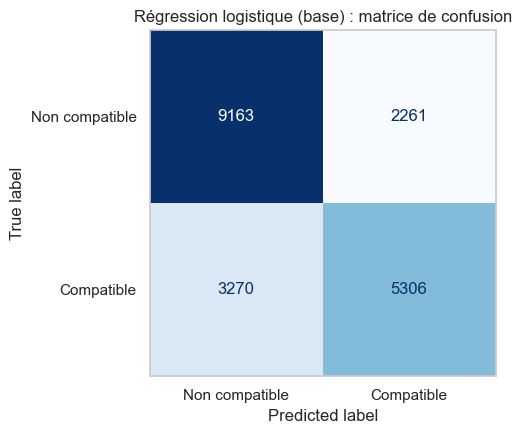

In [9]:
# ============================================================
# Rapport de classification, surapprentissage et matrice de confusion
# ============================================================
pred_base = (proba_base >= 0.5).astype(int)
print(classification_report(
    y_test, pred_base, target_names=["Non compatible (0)", "Compatible (1)"], digits=4
))

auc_train = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, proba_base)
print(f"ROC-AUC train : {auc_train:.4f} | ROC-AUC test : {auc_test:.4f} | écart : {auc_train - auc_test:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_base), display_labels=["Non compatible", "Compatible"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Régression logistique (base) : matrice de confusion")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_confusion_matrix.png", dpi=150)
plt.show()

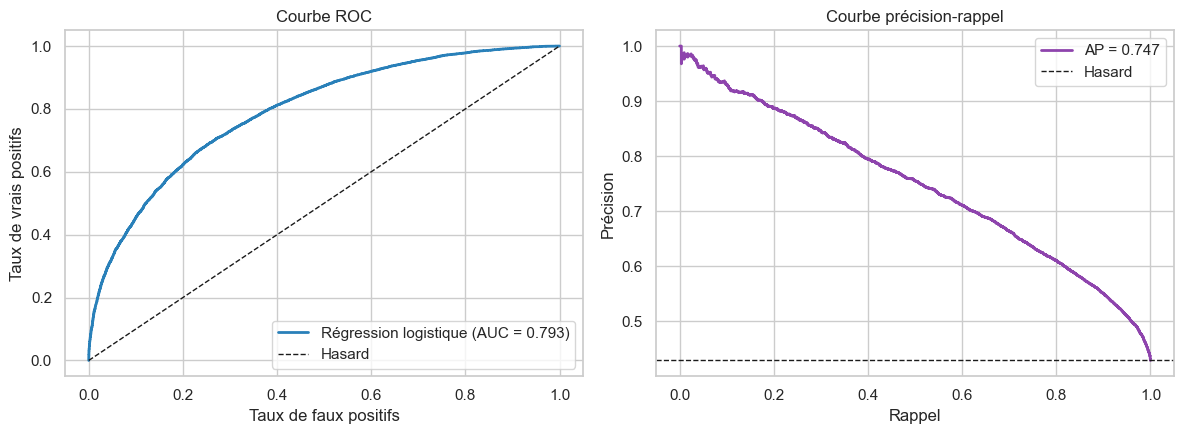

In [10]:
# ============================================================
# Courbe ROC et courbe précision-rappel
# ============================================================
fpr, tpr, _ = roc_curve(y_test, proba_base)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, proba_base)
auc = roc_auc_score(y_test, proba_base)
ap = average_precision_score(y_test, proba_base)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(fpr, tpr, color="#2980b9", linewidth=2, label=f"Régression logistique (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Hasard")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs")
axes[0].set_title("Courbe ROC")
axes[0].legend(loc="lower right")

axes[1].plot(rec_curve, prec_curve, color="#8e44ad", linewidth=2, label=f"AP = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=1, label="Hasard")
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].set_title("Courbe précision-rappel")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_roc_pr_curves.png", dpi=150)
plt.show()

In [11]:
# ============================================================
# Validation croisée stratifiée (5 blocs) sur le train
# ============================================================
cv_summary, cv_details = run_cross_validation(
    CupidLogisticRegression,
    {"max_iter": 1000, "random_state": RANDOM_STATE},
    X_train, y_train,
    n_splits=N_SPLITS, random_state=RANDOM_STATE,
)

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
cv_table = pd.DataFrame({
    "Métrique": metric_names,
    "Moyenne (CV)": [cv_summary[f"mean_{m}"] for m in metric_names],
    "Écart-type (CV)": [cv_summary[f"std_{m}"] for m in metric_names],
    "Test": [results[0][m] for m in metric_names],
})
display(cv_table.round(4))

print(f"ROC-AUC en validation croisée : {cv_summary['mean_ROC-AUC']:.4f} (+/- {cv_summary['std_ROC-AUC']:.4f})")
print("Le score de test est cohérent avec la validation croisée : pas de surapprentissage.")

,Métrique,Moyenne (CV),Écart-type (CV),Test
0,Accuracy,0.7265,0.0033,0.7234
1,Precision,0.7065,0.0046,0.7012
2,Recall,0.6194,0.0047,0.6187
3,F1-Score,0.6601,0.0042,0.6574
4,ROC-AUC,0.7965,0.0028,0.7934


ROC-AUC en validation croisée : 0.7965 (+/- 0.0028)
Le score de test est cohérent avec la validation croisée : pas de surapprentissage.


In [12]:
# ============================================================
# Recherche sur grille (GridSearchCV)
# ============================================================
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

param_grid = [
    {
        "solver": ["lbfgs"], "penalty": ["l2"],
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "class_weight": [None, "balanced"],
    },
    {
        "solver": ["liblinear"], "penalty": ["l1"],
        "C": [0.01, 0.1],
        "class_weight": [None, "balanced"],
    },
]

grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
grid.fit(X_train, y_train)

print("Meilleurs hyperparamètres :", grid.best_params_)
print(f"Meilleur ROC-AUC en validation croisée : {grid.best_score_:.4f}")

Meilleurs hyperparamètres : {'C': 0.01, 'class_weight': None, 'penalty': 'l2', 'solver': 'lbfgs'}
Meilleur ROC-AUC en validation croisée : 0.7965


,penalty,solver,C,class_weight,ROC-AUC (moyenne CV),ROC-AUC (écart-type CV),Rang
0,l2,lbfgs,0.01,NaN,0.79648,0.00282,1
1,l1,liblinear,0.10,NaN,0.79647,0.00279,2
2,l2,lbfgs,0.10,NaN,0.79647,0.00279,3
3,l2,lbfgs,0.10,balanced,0.79647,0.00279,4
4,l2,lbfgs,0.01,balanced,0.79647,0.00282,5
5,l1,liblinear,0.10,balanced,0.79646,0.00278,6
6,l2,lbfgs,1.00,balanced,0.79646,0.00279,7
7,l2,lbfgs,100.00,balanced,0.79646,0.00279,8
8,l2,lbfgs,10.00,balanced,0.79646,0.00279,9
9,l2,lbfgs,1.00,NaN,0.79646,0.00278,10


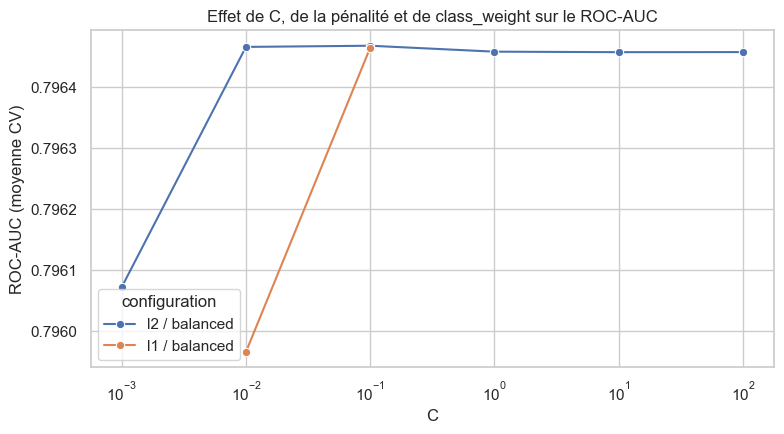

In [13]:
# ============================================================
# Résultats détaillés de la recherche
# ============================================================
tuning = pd.DataFrame(grid.cv_results_)[[
    "param_penalty", "param_solver", "param_C", "param_class_weight",
    "mean_test_score", "std_test_score", "rank_test_score",
]].rename(columns={
    "param_penalty": "penalty",
    "param_solver": "solver",
    "param_C": "C",
    "param_class_weight": "class_weight",
    "mean_test_score": "ROC-AUC (moyenne CV)",
    "std_test_score": "ROC-AUC (écart-type CV)",
    "rank_test_score": "Rang",
}).sort_values("Rang").reset_index(drop=True)

tuning["class_weight"] = tuning["class_weight"].astype(str)
tuning["C"] = tuning["C"].astype(float)

display(tuning.head(10).round(5))
tuning.to_csv(TABLES_DIR / "logistic_regression_tuning.csv", index=False)

plot_df = tuning.copy()
plot_df["configuration"] = plot_df["penalty"] + " / " + plot_df["class_weight"]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=plot_df, x="C", y="ROC-AUC (moyenne CV)", hue="configuration", marker="o", ax=ax)
ax.set_xscale("log")
ax.set_title("Effet de C, de la pénalité et de class_weight sur le ROC-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_tuning_curve.png", dpi=150)
plt.show()

In [14]:
# ============================================================
# Évaluation du modèle réglé sur le jeu de test
# ============================================================
best_model = grid.best_estimator_
proba_tuned = best_model.predict_proba(X_test)[:, 1]

results.append(evaluate_proba(y_test, proba_tuned, 0.5, "Réglé (test)"))
display(pd.DataFrame(results).round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,LogLoss
0,Base (test),0.5,0.7234,0.7012,0.6187,0.6574,0.7934,0.7475,0.5398
1,Réglé (test),0.5,0.7239,0.7021,0.6185,0.6577,0.7934,0.7476,0.5397


Seuil optimal (F1 maximal en validation croisée) : 0.34
F1 en validation croisée à ce seuil : 0.6946


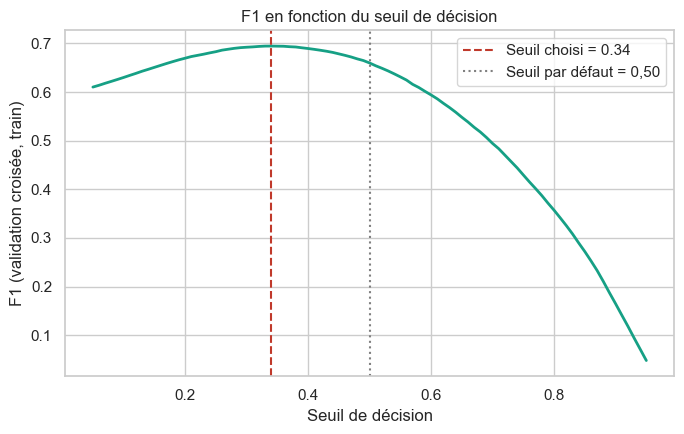

In [15]:
# ============================================================
# Seuil maximisant le F1 (prédictions de validation croisée sur le train)
# ============================================================
proba_cv = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
f1_scores = [f1_score(y_train, (proba_cv >= t).astype(int)) for t in thresholds]

best_threshold = float(thresholds[int(np.argmax(f1_scores))])
print(f"Seuil optimal (F1 maximal en validation croisée) : {best_threshold:.2f}")
print(f"F1 en validation croisée à ce seuil : {max(f1_scores):.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, f1_scores, color="#16a085", linewidth=2)
ax.axvline(best_threshold, color="#c0392b", linestyle="--", label=f"Seuil choisi = {best_threshold:.2f}")
ax.axvline(0.5, color="gray", linestyle=":", label="Seuil par défaut = 0,50")
ax.set_xlabel("Seuil de décision")
ax.set_ylabel("F1 (validation croisée, train)")
ax.set_title("F1 en fonction du seuil de décision")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_threshold.png", dpi=150)
plt.show()

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,LogLoss
0,Base (test),0.50,0.7234,0.7012,0.6187,0.6574,0.7934,0.7475,0.5398
1,Réglé (test),0.50,0.7239,0.7021,0.6185,0.6577,0.7934,0.7476,0.5397
2,Réglé + seuil optimal (test),0.34,0.6914,0.6046,0.8099,0.6923,0.7934,0.7476,0.5397


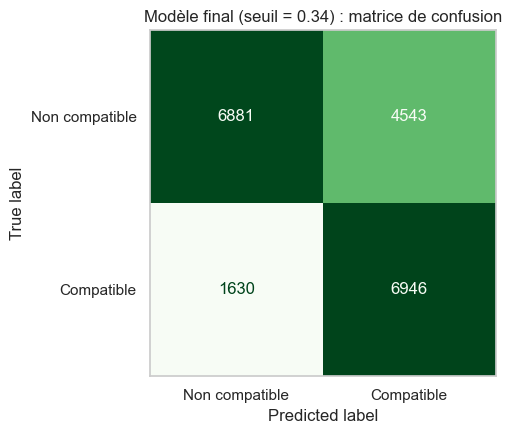

In [16]:
# ============================================================
# Comparaison finale sur le jeu de test
# ============================================================
results.append(evaluate_proba(y_test, proba_tuned, best_threshold, "Réglé + seuil optimal (test)"))

final_table = pd.DataFrame(results)
display(final_table.round(4))
final_table.to_csv(TABLES_DIR / "logistic_regression_metrics.csv", index=False)

pred_final = (proba_tuned >= best_threshold).astype(int)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_final), display_labels=["Non compatible", "Compatible"]
).plot(ax=ax, cmap="Greens", colorbar=False, values_format="d")
ax.set_title(f"Modèle final (seuil = {best_threshold:.2f}) : matrice de confusion")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_final_confusion_matrix.png", dpi=150)
plt.show()

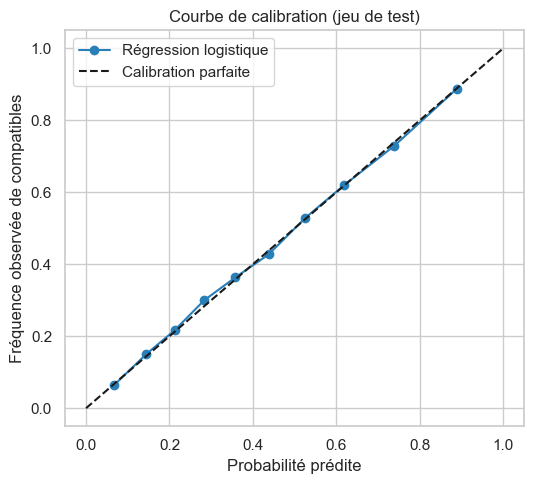

In [17]:
# ============================================================
# Calibration des probabilités
# ============================================================
prob_true, prob_pred = calibration_curve(y_test, proba_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(prob_pred, prob_true, marker="o", color="#2980b9", label="Régression logistique")
ax.plot([0, 1], [0, 1], "k--", label="Calibration parfaite")
ax.set_xlabel("Probabilité prédite")
ax.set_ylabel("Fréquence observée de compatibles")
ax.set_title("Courbe de calibration (jeu de test)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_calibration.png", dpi=150)
plt.show()

Constante (intercept) : -0.2485
Variables dont le coefficient vaut exactement 0 (L1) : 0


,Variable,Groupe,Coefficient,Odds ratio
0,same_love_language,construite,0.8041,2.2346
1,diff_career_ambition,construite,-0.4956,0.6092
2,diff_emotional_expressiveness,construite,-0.3915,0.6761
3,avg_trait_diff,construite,-0.3473,0.7066
4,same_career_field,construite,0.2010,1.2227
5,diff_spontaneity,construite,-0.1974,0.8208
6,b_career_field_Creative Arts,catégorielle (one-hot),-0.1659,0.8471
7,big5_harmony_score,construite,0.1599,1.1734
8,same_location,construite,0.1453,1.1564
9,a_career_field_Creative Arts,catégorielle (one-hot),-0.1385,0.8706


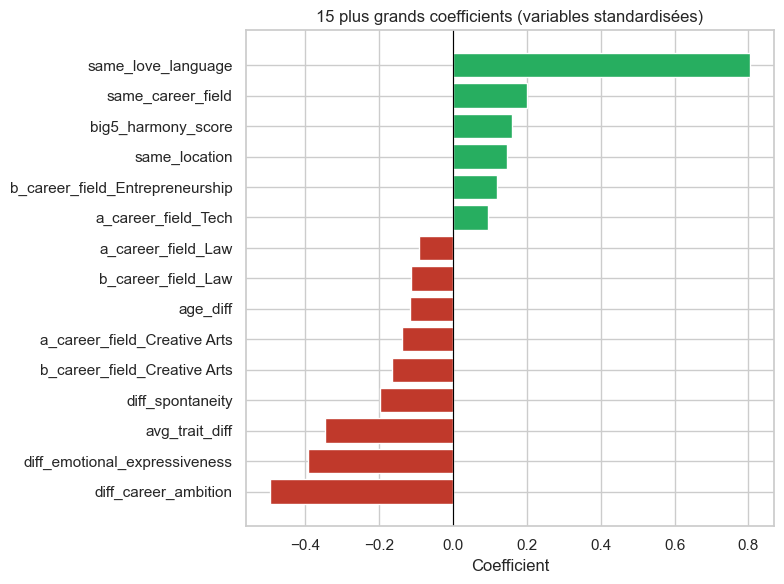

In [18]:
# ============================================================
# Coefficients et odds ratios
# ============================================================
final_logreg = best_model

def feature_group(name):
    if name in CAT_NAMES:
        return "catégorielle (one-hot)"
    if name in preprocessor.numerical_raw_cols:
        return "numérique brute"
    return "construite"

coef_df = pd.DataFrame({
    "Variable": FEATURE_NAMES,
    "Groupe": [feature_group(n) for n in FEATURE_NAMES],
    "Coefficient": final_logreg.coef_[0],
})
coef_df["Odds ratio"] = np.exp(coef_df["Coefficient"])
coef_df["|Coefficient|"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("|Coefficient|", ascending=False).reset_index(drop=True)

print("Constante (intercept) :", round(float(final_logreg.intercept_[0]), 4))
print("Variables dont le coefficient vaut exactement 0 (L1) :", int((coef_df["Coefficient"] == 0).sum()))
display(coef_df.drop(columns="|Coefficient|").head(15).round(4))

coef_df.drop(columns="|Coefficient|").to_csv(
    TABLES_DIR / "logistic_regression_coefficients.csv", index=False
)

top = coef_df.head(15).sort_values("Coefficient")
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#c0392b" if v < 0 else "#27ae60" for v in top["Coefficient"]]
ax.barh(top["Variable"], top["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("15 plus grands coefficients (variables standardisées)")
ax.set_xlabel("Coefficient")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_coefficients.png", dpi=150)
plt.show()

,Variable,Groupe,Baisse de ROC-AUC (moyenne),Écart-type
0,same_love_language,construite,0.1076,0.0020
1,diff_career_ambition,construite,0.0391,0.0017
2,diff_emotional_expressiveness,construite,0.0227,0.0009
3,avg_trait_diff,construite,0.0195,0.0018
4,same_career_field,construite,0.0075,0.0015
5,diff_spontaneity,construite,0.0069,0.0005
6,big5_harmony_score,construite,0.0048,0.0005
7,same_location,construite,0.0032,0.0004
8,age_diff,construite,0.0027,0.0004
9,diff_chronotype,construite,0.0010,0.0004


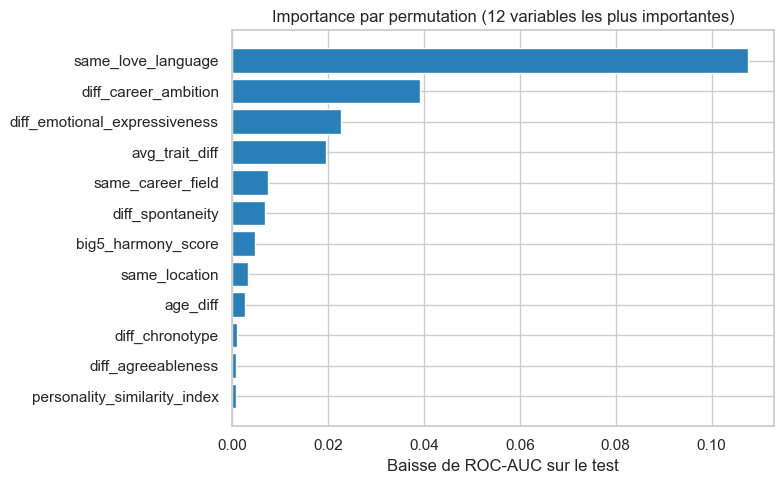

In [19]:
# ============================================================
# Importance par permutation (jeu de test, critère ROC-AUC)
# ============================================================
perm = permutation_importance(
    final_logreg, X_test, y_test,
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)

perm_df = pd.DataFrame({
    "Variable": FEATURE_NAMES,
    "Groupe": [feature_group(n) for n in FEATURE_NAMES],
    "Baisse de ROC-AUC (moyenne)": perm.importances_mean,
    "Écart-type": perm.importances_std,
}).sort_values("Baisse de ROC-AUC (moyenne)", ascending=False).reset_index(drop=True)

display(perm_df.head(10).round(4))
perm_df.to_csv(TABLES_DIR / "logistic_regression_permutation_importance.csv", index=False)

top_perm = perm_df.head(12).sort_values("Baisse de ROC-AUC (moyenne)")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_perm["Variable"], top_perm["Baisse de ROC-AUC (moyenne)"], color="#2980b9")
ax.set_title("Importance par permutation (12 variables les plus importantes)")
ax.set_xlabel("Baisse de ROC-AUC sur le test")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logistic_regression_permutation_importance.png", dpi=150)
plt.show()

In [20]:
# ============================================================
# Multicolinéarité : facteur d'inflation de la variance (VIF)
# sur le bloc des variables numériques (hors indicatrices one-hot)
# ============================================================
num_idx = [FEATURE_NAMES.index(n) for n in NUM_NAMES]
Z = X_train[:, num_idx]

vif_values = []
for j, name in enumerate(NUM_NAMES):
    others = [k for k in range(Z.shape[1]) if k != j]
    reg = LinearRegression().fit(Z[:, others], Z[:, j])
    r2 = reg.score(Z[:, others], Z[:, j])
    vif_values.append(np.inf if (1.0 - r2) < 1e-10 else 1.0 / (1.0 - r2))

vif_df = pd.DataFrame({"Variable": NUM_NAMES, "VIF": vif_values}).sort_values(
    "VIF", ascending=False
).reset_index(drop=True)

display(vif_df.head(14))

n_inf = int(np.isinf(vif_df["VIF"]).sum())
n_high = int((vif_df["VIF"] > 10).sum())
print(f"Variables parfaitement redondantes (VIF infini) : {n_inf}")
print(f"Variables avec un VIF supérieur à 10            : {n_high} sur {len(vif_df)}")
print("La redondance vient des variables construites ; la régularisation L2 la rend sans conséquence pour la prédiction.")
vif_df.to_csv(TABLES_DIR / "logistic_regression_vif.csv", index=False)

,Variable,VIF
0,diff_openness,inf
1,diff_career_ambition,inf
2,diff_emotional_expressiveness,inf
3,diff_spontaneity,inf
4,diff_chronotype,inf
5,diff_conscientiousness,inf
6,diff_extraversion,inf
7,diff_agreeableness,inf
8,avg_trait_diff,inf
9,big5_harmony_score,146.345666


Variables parfaitement redondantes (VIF infini) : 9
Variables avec un VIF supérieur à 10            : 12 sur 37
La redondance vient des variables construites ; la régularisation L2 la rend sans conséquence pour la prédiction.


In [21]:
# ============================================================
# Comparaison avec results/model_comparison.csv (produit par src/train_and_evaluate.py)
# ============================================================
team_path = ROOT / "results" / "model_comparison.csv"
cols = ["Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

mine = pd.DataFrame([evaluate_proba(y_test, proba_tuned, 0.5, "Logistic Regression (ce notebook, réglé)")])[cols]

if team_path.exists() and team_path.stat().st_size > 0:
    team = pd.read_csv(team_path)[cols]
    comparison = pd.concat([team, mine], ignore_index=True)
else:
    print("results/model_comparison.csv absent ou vide : seul le résultat de ce notebook est affiché.")
    comparison = mine

comparison = comparison.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.7241,0.7016,0.6206,0.6586,0.7960
1,"Logistic Regression (ce notebook, réglé)",0.7239,0.7021,0.6185,0.6577,0.7934
2,Logistic Regression,0.7234,0.7012,0.6187,0.6574,0.7934
3,Random Forest,0.7166,0.6991,0.5954,0.6431,0.7882
4,Decision Tree,0.6869,0.6578,0.5623,0.6063,0.7255


In [22]:
# ============================================================
# Sauvegarde des prédictions sur le jeu de test
# ============================================================
predictions = pd.DataFrame({
    "y_true": np.asarray(y_test),
    "y_proba": proba_tuned,
    "y_pred": pred_final,
})
predictions.index.name = "test_row"
predictions.to_csv(TABLES_DIR / "logistic_regression_predictions.csv")

expected_files = [
    "logistic_regression_metrics.csv",
    "logistic_regression_tuning.csv",
    "logistic_regression_coefficients.csv",
    "logistic_regression_permutation_importance.csv",
    "logistic_regression_vif.csv",
    "logistic_regression_predictions.csv",
]
print("Fichiers enregistrés dans results/tables :")
for name in expected_files:
    path = TABLES_DIR / name
    assert path.exists() and path.stat().st_size > 0, f"{name} manquant ou vide"
    print(f" - {name}")

assert len(predictions) == len(y_test)
assert set(predictions["y_pred"].unique()).issubset({0, 1})
print("\nContrôles finaux réussis.")

Fichiers enregistrés dans results/tables :
 - logistic_regression_metrics.csv
 - logistic_regression_tuning.csv
 - logistic_regression_coefficients.csv
 - logistic_regression_permutation_importance.csv
 - logistic_regression_vif.csv
 - logistic_regression_predictions.csv

Contrôles finaux réussis.


In [24]:
# ============================================================
# Résumé final
# ============================================================
final_row = final_table.iloc[-1]

print("RÉSUMÉ - RÉGRESSION LOGISTIQUE")
print("-" * 60)
print("Meilleurs hyperparamètres :", grid.best_params_)
print(f"Seuil de décision         : {best_threshold:.2f}")
print(f"Accuracy (test)           : {final_row['Accuracy']:.4f}")
print(f"Précision (test)          : {final_row['Precision']:.4f}")
print(f"Rappel (test)             : {final_row['Recall']:.4f}")
print(f"F1 (test)                 : {final_row['F1-Score']:.4f}")
print(f"ROC-AUC (test)            : {final_row['ROC-AUC']:.4f}")
print()
print("Variables les plus importantes (permutation) :")
for _, row in perm_df.head(5).iterrows():
    print(f" - {row['Variable']:32s} baisse de ROC-AUC = {row['Baisse de ROC-AUC (moyenne)']:.4f}")

RÉSUMÉ - RÉGRESSION LOGISTIQUE
------------------------------------------------------------
Meilleurs hyperparamètres : {'C': 0.01, 'class_weight': None, 'penalty': 'l2', 'solver': 'lbfgs'}
Seuil de décision         : 0.34
Accuracy (test)           : 0.6914
Précision (test)          : 0.6046
Rappel (test)             : 0.8099
F1 (test)                 : 0.6923
ROC-AUC (test)            : 0.7934

Variables les plus importantes (permutation) :
 - same_love_language               baisse de ROC-AUC = 0.1076
 - diff_career_ambition             baisse de ROC-AUC = 0.0391
 - diff_emotional_expressiveness    baisse de ROC-AUC = 0.0227
 - avg_trait_diff                   baisse de ROC-AUC = 0.0195
 - same_career_field                baisse de ROC-AUC = 0.0075
